In [1]:
# Import core machine learning, preprocessing, and visualization libraries
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, brier_score_loss, classification_report
)

# Suppress OpenMP multi-thread runtime library conflict warnings
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
# Load the enriched women's clothing customer reviews classification dataset
dataset_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("05-11-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded. Total records: {df.shape[0]}, Features: {df.shape[1]}")
display(df[['Clothing ID', 'Age', 'Department Name', 'Rating', 'Sentiment_Compound', 'Recommended IND']].head())


Dataset successfully loaded. Total records: 23486, Features: 23


,Clothing ID,Age,Department Name,Rating,Sentiment_Compound,Recommended IND
0,767,33,Intimate,4,0.8932,1
1,1080,34,Dresses,5,0.9729,1
2,1077,60,Dresses,3,0.9427,0
3,1049,50,Bottoms,5,0.7182,1
4,847,47,Tops,5,0.9436,1


In [3]:
# Feature Engineering: Combine TF-IDF text features with structured tabular metadata
# Impute any missing review text with an empty string
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

# Extract top 250 unigrams and bigrams using TF-IDF vectorization
tfidf_model = TfidfVectorizer(max_features=250, stop_words='english', ngram_range=(1, 2))
X_text = tfidf_model.fit_transform(df['Full_Review_Text']).toarray()
text_names = [f"tfidf_{w}" for w in tfidf_model.get_feature_names_out()]

# Select numerical sentiment scores, counts, and customer demographic attributes
numeric_cols = [
    'Age', 'Positive Feedback Count', 'Review_Length', 'Review_Word_Count',
    'Exclamation_Count', 'Sentiment_Compound', 'Sentiment_Pos',
    'Sentiment_Neg', 'Positive_Word_Count', 'Negative_Word_Count', 'Fit_Issue_Word_Count'
]
X_num = df[numeric_cols].fillna(0).values

# Apply one-hot encoding to department category features
dept_dummies = pd.get_dummies(df['Department Name'].fillna('Unknown'), prefix='dept', drop_first=True)
dept_names = dept_dummies.columns.tolist()
X_dept = dept_dummies.values

# Concatenate all tabular and vectorized text features into the final feature matrix
X = np.hstack([X_text, X_num, X_dept])
y = df['Recommended IND'].values
feature_names = text_names + numeric_cols + dept_names

print(f"Final feature space dimensions: {X.shape[0]} rows x {X.shape[1]} features.")


Final feature space dimensions: 23486 rows x 266 features.


In [4]:
# Stratified Data Partitioning: 70% Training, 15% Validation, and 15% Holdout Test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Split remaining 85% into 70% train and 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765, stratify=y_train_full, random_state=42
)

print(f"Partition summary -> Training: {X_train.shape[0]}, Validation: {X_val.shape[0]}, Holdout Test: {X_test.shape[0]}")


Partition summary -> Training: 16439, Validation: 3524, Holdout Test: 3523


In [5]:
# Load and inspect the precomputed hyperparameter tuning experiments table
tuning_csv = "xgboost_hyperparameter_tuning_experiments.csv"
if not os.path.exists(tuning_csv):
    tuning_csv = os.path.join("05-11-2026", "Task 1", "xgboost_hyperparameter_tuning_experiments.csv")

df_tuning_results = pd.read_csv(tuning_csv)
print("Top 10 Hyperparameter Configurations ranked by Validation Log Loss:")
display(df_tuning_results.sort_values(by=['Val_Log_Loss', 'Val_ROC_AUC'], ascending=[True, False]).head(10))


Top 10 Hyperparameter Configurations ranked by Validation Log Loss:


,Learning_Rate,Max_Depth,Subsample,Gamma,Best_Iteration,Train_Log_Loss,Val_Log_Loss,Generalization_Gap,Val_ROC_AUC,Val_F1,Val_Accuracy,Fit_Time_Sec
9,0.10,5,0.8,0.5,234,0.1524,0.2450,0.0926,0.9296,0.9367,0.8936,17.25
26,0.10,5,1.0,2.0,245,0.1533,0.2459,0.0926,0.9298,0.9361,0.8922,11.66
10,0.10,7,0.8,0.5,227,0.1099,0.2463,0.1364,0.9296,0.9374,0.8947,27.15
21,0.10,5,0.8,1.0,237,0.1520,0.2467,0.0946,0.9292,0.9348,0.8902,15.78
22,0.10,5,0.8,2.0,233,0.1552,0.2468,0.0916,0.9288,0.9370,0.8939,24.33
20,0.10,5,0.8,0.0,229,0.1523,0.2473,0.0949,0.9280,0.9347,0.8902,13.88
24,0.10,5,1.0,0.5,219,0.1568,0.2476,0.0909,0.9285,0.9365,0.8930,11.99
23,0.10,5,1.0,0.0,230,0.1536,0.2478,0.0942,0.9284,0.9363,0.8927,12.34
16,0.10,5,0.6,0.0,206,0.1624,0.2480,0.0856,0.9282,0.9356,0.8916,11.42
7,0.05,9,0.8,0.5,248,0.1128,0.2485,0.1356,0.9283,0.9360,0.8922,31.18


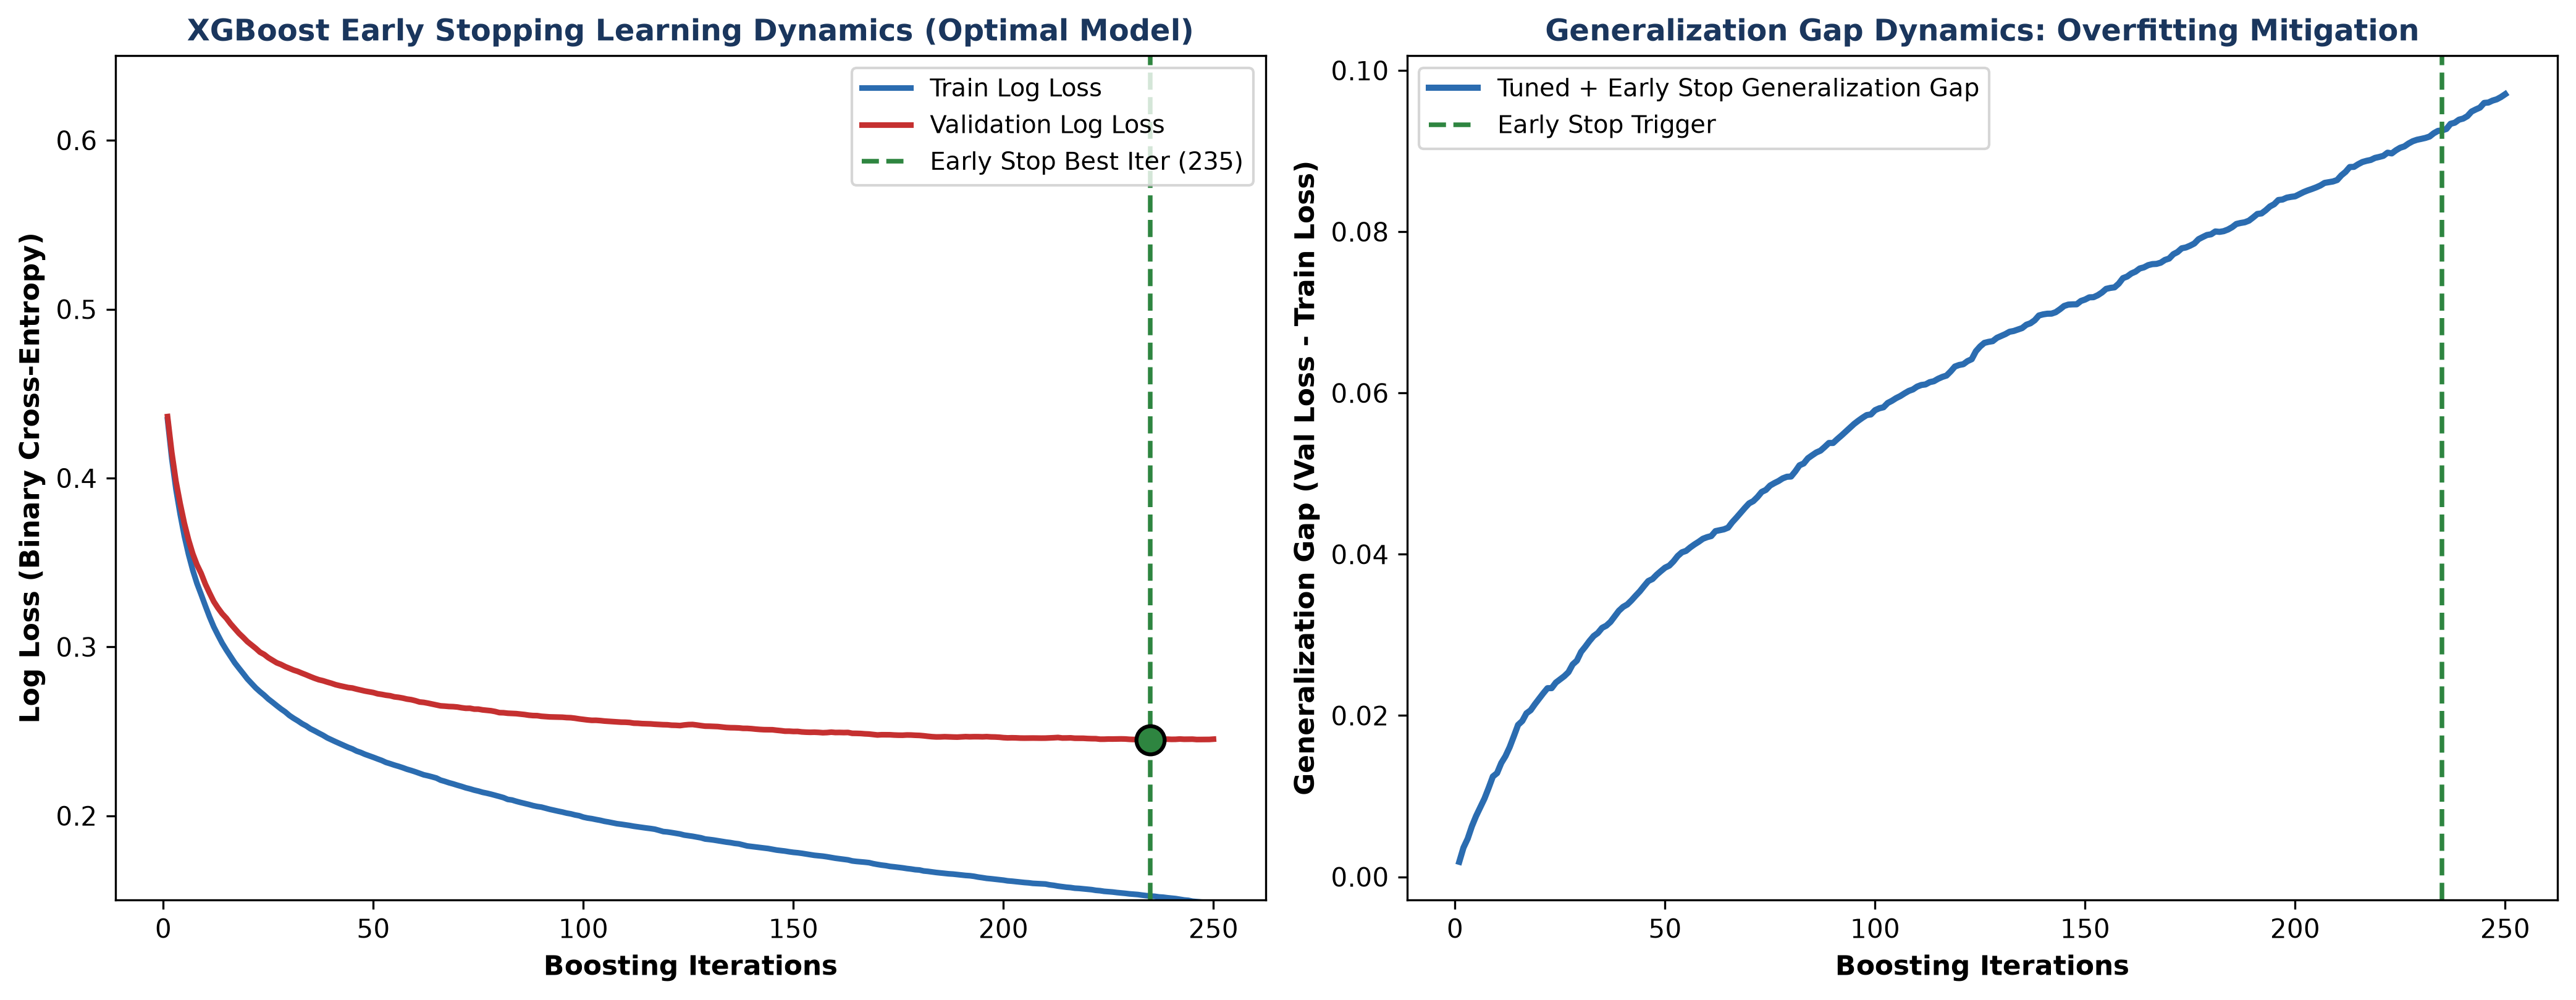

In [6]:
# Display Figure 1: Early Stopping Iteration Curves & Generalization Gap Comparison
# Load early stopping iteration history log
history_csv = "xgboost_early_stopping_iteration_history.csv"
if not os.path.exists(history_csv):
    history_csv = os.path.join("05-11-2026", "Task 1", "xgboost_early_stopping_iteration_history.csv")
df_history = pd.read_csv(history_csv)

# Plot training vs validation loss curves across boosting iterations
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
min_idx = df_history['Val_Log_Loss'].idxmin()
best_iter_val = int(df_history.loc[min_idx, 'Iteration'])
best_val_loss_val = float(df_history.loc[min_idx, 'Val_Log_Loss'])

axes[0].plot(df_history['Iteration'], df_history['Train_Log_Loss'], label='Train Log Loss', color='#2B6CB0', linewidth=2.2)
axes[0].plot(df_history['Iteration'], df_history['Val_Log_Loss'], label='Validation Log Loss', color='#C53030', linewidth=2.2)
axes[0].axvline(x=best_iter_val, color='#2E8540', linestyle='--', linewidth=1.8, label=f'Early Stop Best Iter ({best_iter_val})')
axes[0].scatter([best_iter_val], [best_val_loss_val], color='#2E8540', s=120, zorder=5, edgecolor='black', linewidth=1.5)
axes[0].set_title("XGBoost Early Stopping Learning Dynamics (Optimal Model)", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[0].set_xlabel("Boosting Iterations", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Log Loss (Binary Cross-Entropy)", fontsize=10.5, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, fontsize=9.5)
axes[0].set_ylim(0.15, 0.65)

# Plot generalization gap showing how early stopping prevents validation loss divergence
axes[1].plot(df_history['Iteration'], df_history['Loss_Difference'], label='Tuned + Early Stop Generalization Gap', color='#2B6CB0', linewidth=2.4)
axes[1].axvline(x=best_iter_val, color='#2E8540', linestyle='--', linewidth=1.8, label='Early Stop Trigger')
axes[1].set_title("Generalization Gap Dynamics: Overfitting Mitigation", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[1].set_xlabel("Boosting Iterations", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Generalization Gap (Val Loss - Train Loss)", fontsize=10.5, fontweight='bold')
axes[1].legend(loc='upper left', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()


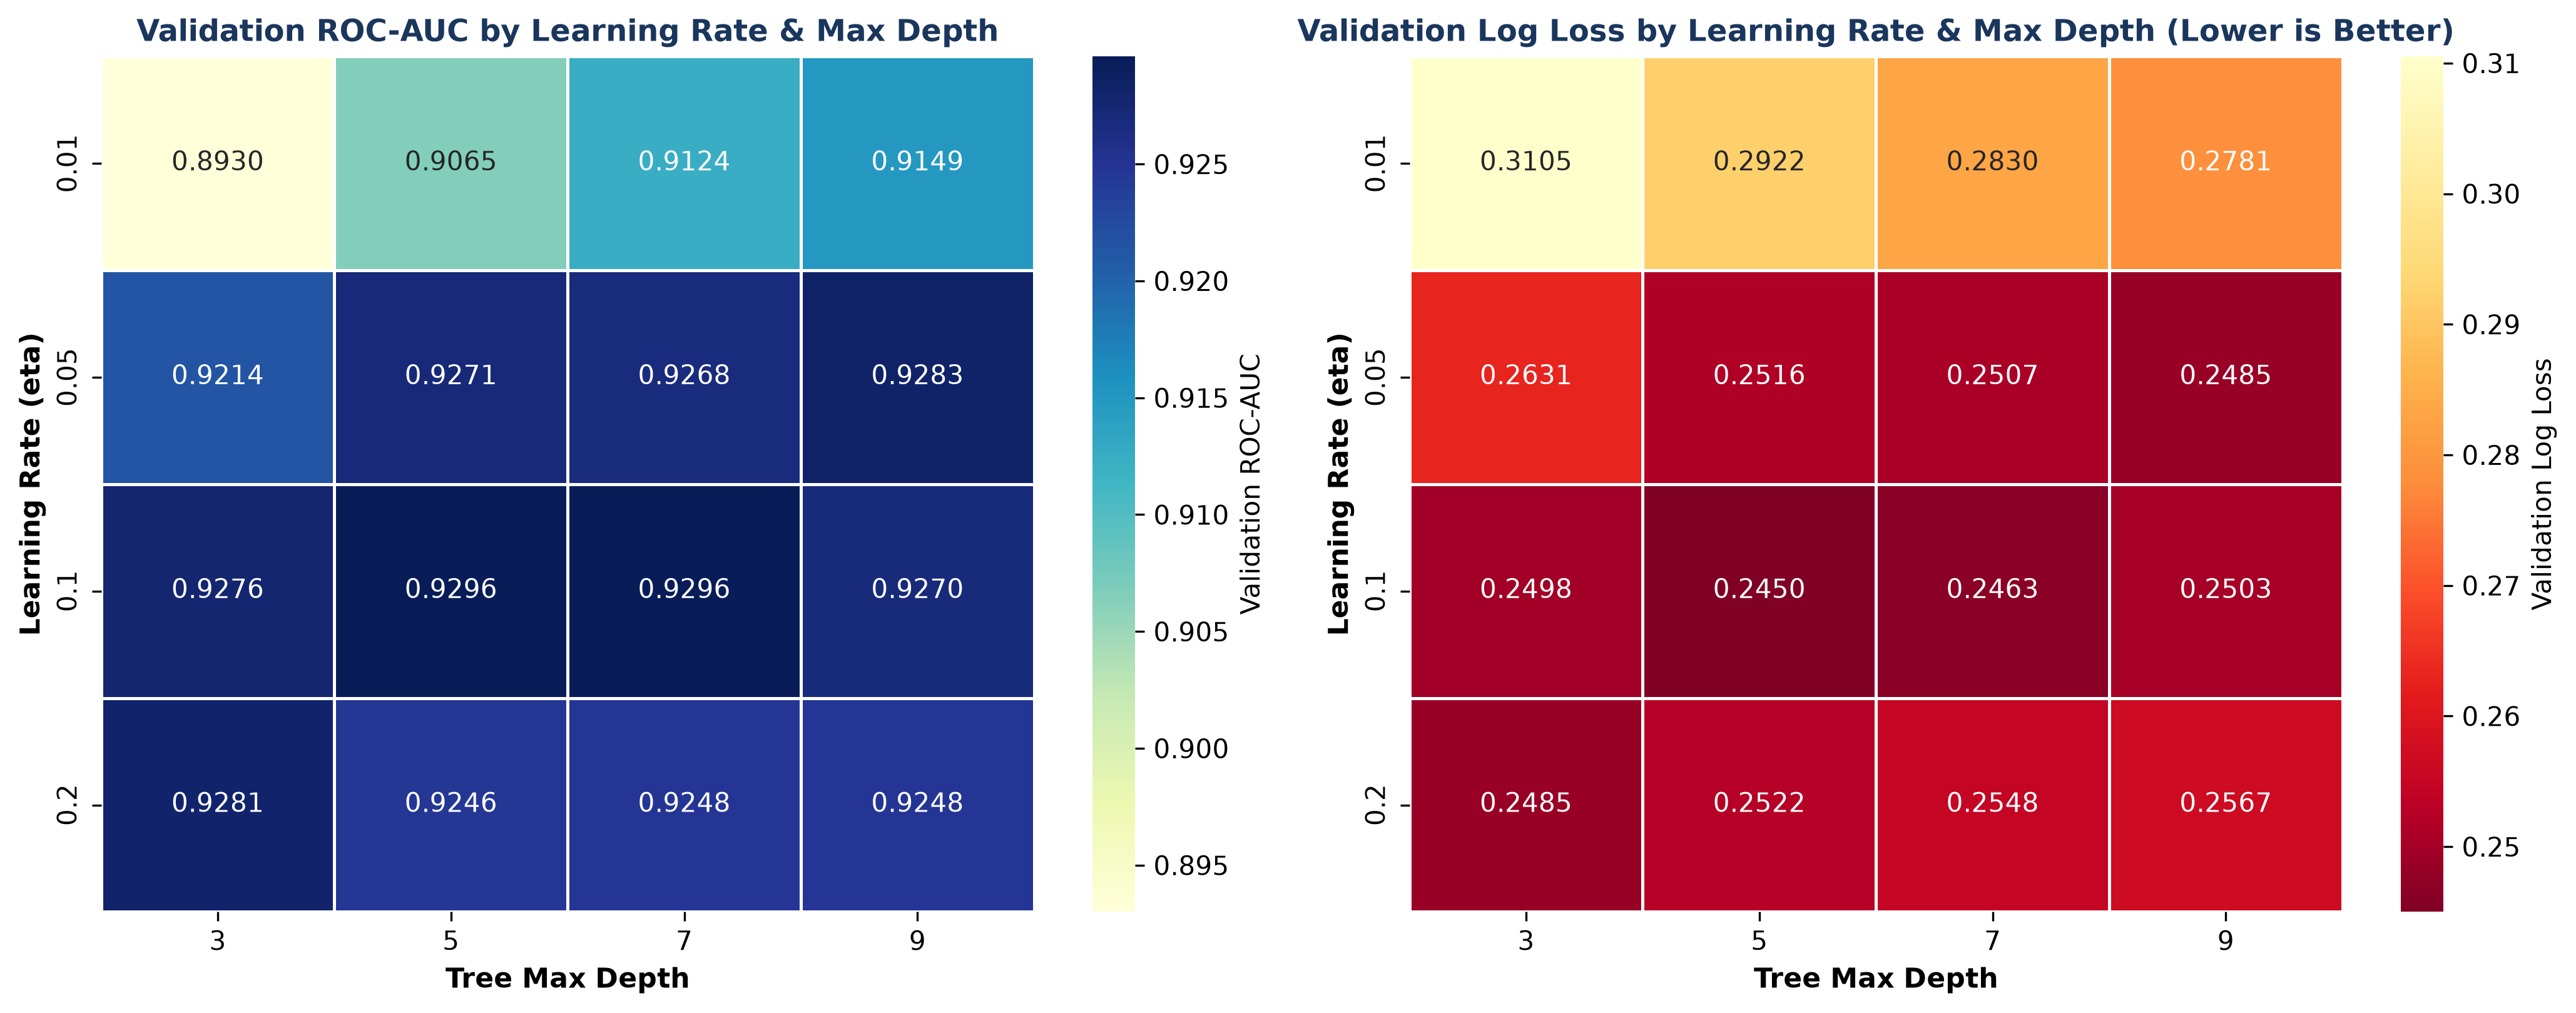

In [7]:
# Display Figure 2: Learning Rate and Tree Depth Interaction Heatmaps
pivot_roc_grid = df_tuning_results[(df_tuning_results['Subsample'] == 0.8) & (df_tuning_results['Gamma'] == 0.5)].pivot(index='Learning_Rate', columns='Max_Depth', values='Val_ROC_AUC')
pivot_loss_grid = df_tuning_results[(df_tuning_results['Subsample'] == 0.8) & (df_tuning_results['Gamma'] == 0.5)].pivot(index='Learning_Rate', columns='Max_Depth', values='Val_Log_Loss')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
sns.heatmap(pivot_roc_grid, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'Validation ROC-AUC'}, ax=axes[0], linewidths=1.2, linecolor='white')
axes[0].set_title("Validation ROC-AUC by Learning Rate & Max Depth", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[0].set_xlabel("Tree Max Depth", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Learning Rate (eta)", fontsize=10.5, fontweight='bold')

sns.heatmap(pivot_loss_grid, annot=True, fmt=".4f", cmap="YlOrRd_r", cbar_kws={'label': 'Validation Log Loss'}, ax=axes[1], linewidths=1.2, linecolor='white')
axes[1].set_title("Validation Log Loss by Learning Rate & Max Depth (Lower is Better)", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[1].set_xlabel("Tree Max Depth", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Learning Rate (eta)", fontsize=10.5, fontweight='bold')

plt.tight_layout()
plt.show()


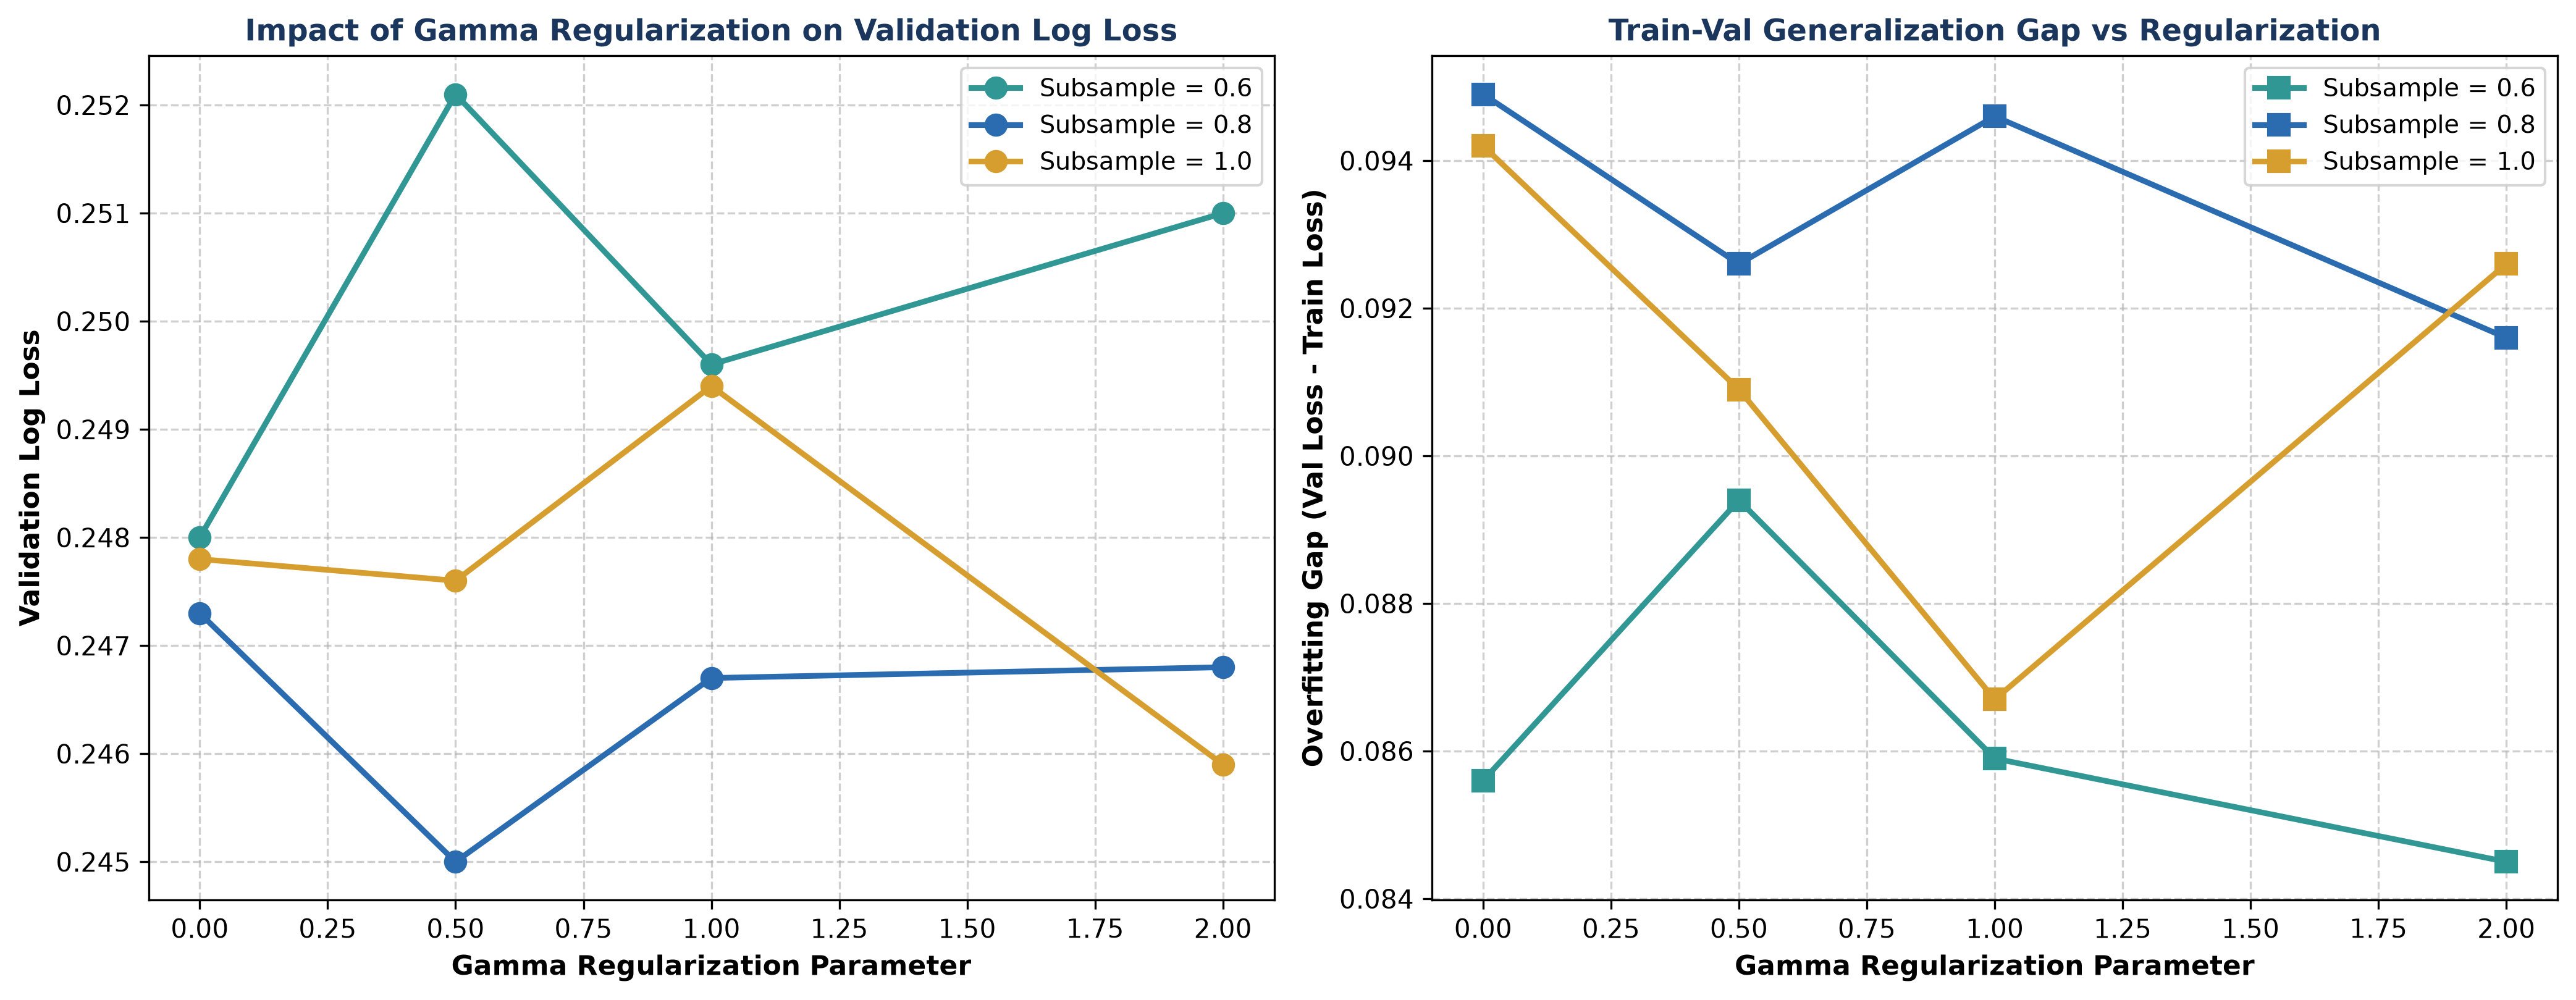

In [8]:
# Display Figure 3: Subsample Ratio and Gamma Regularization Analysis
df_reg_subset = df_tuning_results[(df_tuning_results['Learning_Rate'] == 0.10) & (df_tuning_results['Max_Depth'] == 5)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# Subsample vs Gamma validation loss impact
color_dict = {'0.6': '#319795', '0.8': '#2B6CB0', '1.0': '#D69E2E'}
for sub in [0.6, 0.8, 1.0]:
    sub_df = df_reg_subset[df_reg_subset['Subsample'] == sub].sort_values(by='Gamma')
    axes[0].plot(sub_df['Gamma'], sub_df['Val_Log_Loss'], marker='o', linewidth=2.2, markersize=8,
                 label=f'Subsample = {sub}', color=color_dict[str(sub)])

axes[0].set_title("Impact of Gamma Regularization on Validation Log Loss", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[0].set_xlabel("Gamma Regularization Parameter", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Validation Log Loss", fontsize=10.5, fontweight='bold')
axes[0].legend(frameon=True, fontsize=9.5)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subsample vs Gamma generalization gap
for sub in [0.6, 0.8, 1.0]:
    sub_df = df_reg_subset[df_reg_subset['Subsample'] == sub].sort_values(by='Gamma')
    axes[1].plot(sub_df['Gamma'], sub_df['Generalization_Gap'], marker='s', linewidth=2.2, markersize=8,
                 label=f'Subsample = {sub}', color=color_dict[str(sub)])

axes[1].set_title("Train-Val Generalization Gap vs Regularization", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[1].set_xlabel("Gamma Regularization Parameter", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Overfitting Gap (Val Loss - Train Loss)", fontsize=10.5, fontweight='bold')
axes[1].legend(frameon=True, fontsize=9.5)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


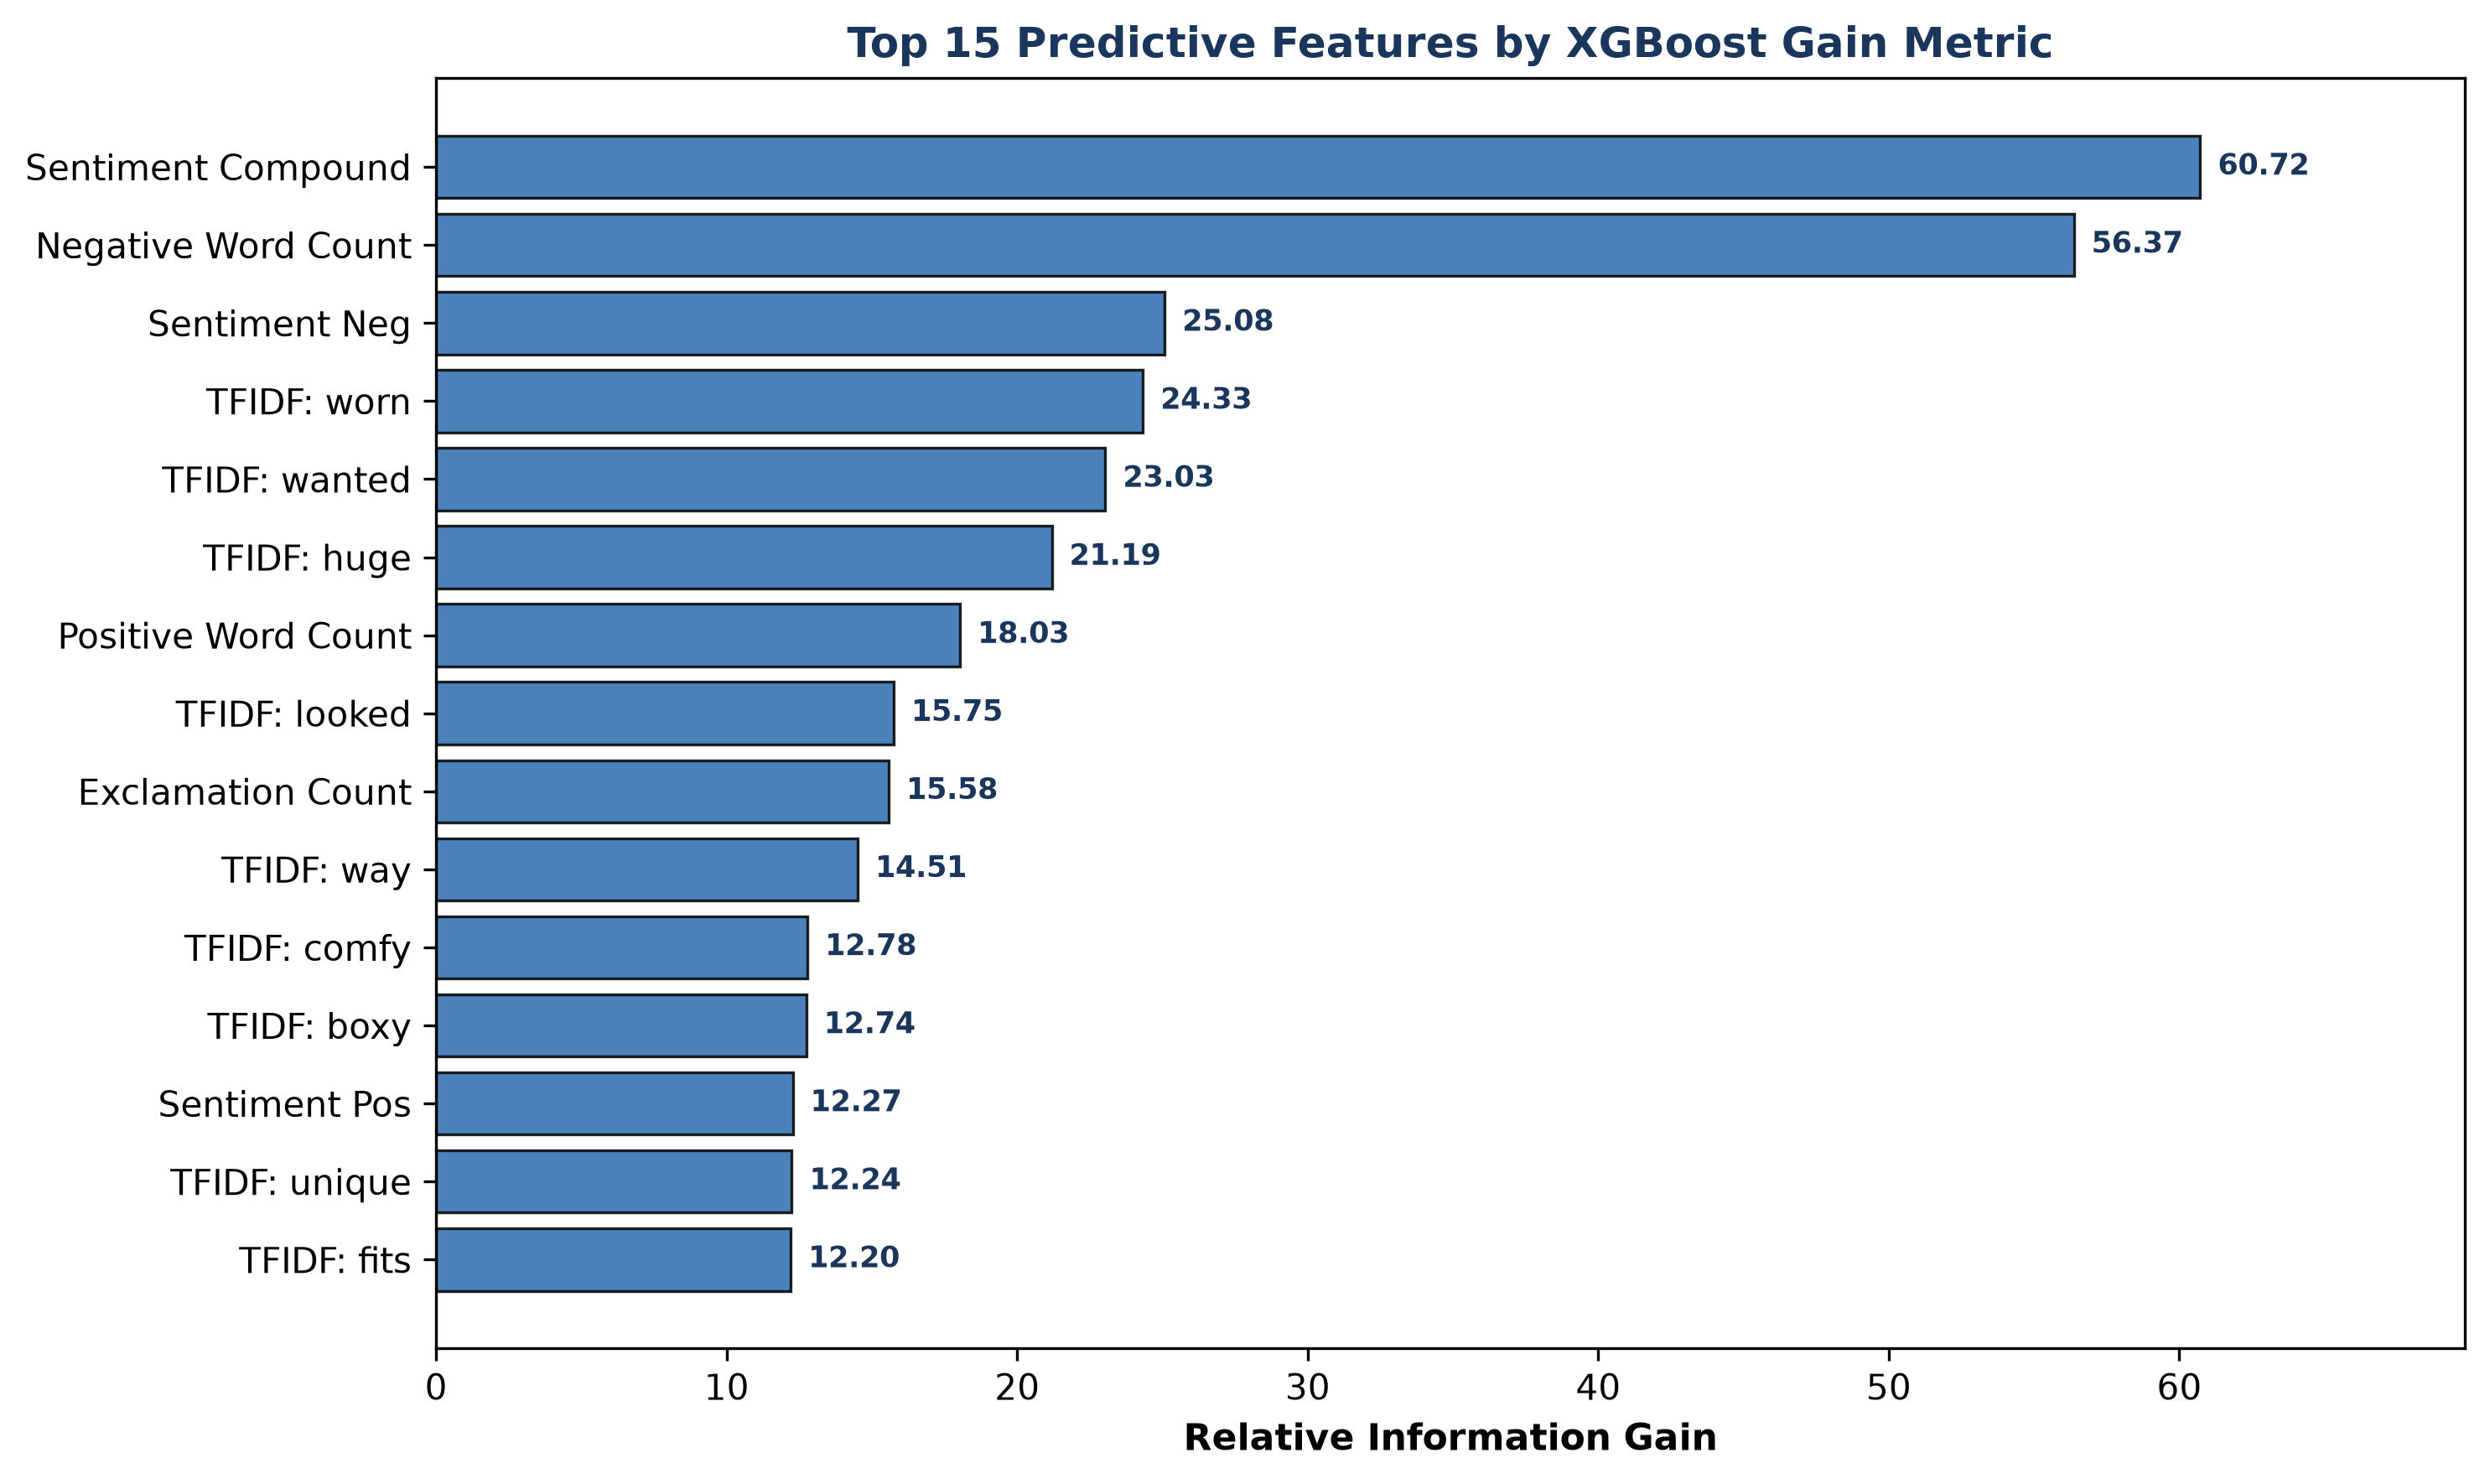

In [9]:
# Display Figure 4: Top Predictive Features by XGBoost Gain
# Load saved optimal model and compute top features
model_file = "xgboost_optimal_model.joblib"
if not os.path.exists(model_file):
    model_file = os.path.join("05-11-2026", "Task 1", "xgboost_optimal_model.joblib")
loaded_xgb = joblib.load(model_file)
booster_scores = loaded_xgb.get_booster().get_score(importance_type='gain')
top15_list = sorted(booster_scores.items(), key=lambda x: x[1], reverse=True)[:15]

t_names = [feature_names[int(k[1:])] if k.startswith('f') and k[1:].isdigit() and int(k[1:]) < len(feature_names) else k for k, v in top15_list][::-1]
t_names_clean = [n.replace('tfidf_', 'TFIDF: ').replace('_', ' ') for n in t_names]
t_scores = [v for k, v in top15_list][::-1]

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
bars = ax.barh(t_names_clean, t_scores, color='#2B6CB0', edgecolor='black', linewidth=0.8, alpha=0.85)
ax.set_title("Top 15 Predictive Features by XGBoost Gain Metric", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Relative Information Gain", fontsize=10.5, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    ax.text(w + max(t_scores)*0.01, bar.get_y() + bar.get_height()/2, f"{w:.2f}",
            va='center', fontsize=8.5, fontweight='bold', color='#1A365D')
ax.set_xlim(0, max(t_scores) * 1.15)
plt.tight_layout()
plt.show()


In [10]:
# Display Holdout Test Set Performance Metrics for Optimal Model
optimal_metrics_csv = "xgboost_optimal_model_evaluation_metrics.csv"
if not os.path.exists(optimal_metrics_csv):
    optimal_metrics_csv = os.path.join("05-11-2026", "Task 1", "xgboost_optimal_model_evaluation_metrics.csv")

df_optimal_display = pd.read_csv(optimal_metrics_csv)
print("Holdout Test Set Performance Evaluation:")
display(df_optimal_display)


Holdout Test Set Performance Evaluation:


,Model_Name,Learning_Rate,Max_Depth,Subsample_Ratio,Gamma_Regularization,Colsample_bytree,Early_Stopping_Rounds,Best_Iteration,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score,Test_ROC_AUC,Test_Log_Loss,Test_Brier_Score
0,XGBoost_Optimal_Regularized,0.1,5,0.8,0.5,0.8,20,234,0.8907,0.9137,0.9575,0.9351,0.9244,0.2553,0.0777
